# VESM: Getting Started (Quickstart & Inference)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ntranoslab/vesm/blob/main/notebooks/VESM_Getting_Started.ipynb)

### Requirements
- Python 3.9+ (recommended), `torch`, `transformers`, `huggingface_hub`, `numpy`, `matplotlib`, `seaborn`
- GPU is optional but recommended for speed

## Table of contents
1. [Setup & Imports](#setup--imports)
2. [Load a VESM Model](#load-a-model)
3. [Run Inference & Get Scores](#vesm_inference)
4. [Visualize Results](#visualize-results)  
5. [Download Prediction Scores](#download-prediction-scores)
6. [VESM3 Inference](#vesm3-inference)

<a id="setup--imports"></a>

## 1. Setup & Imports

In [ ]:
import os
from google.colab import userdata

# Retrieve Hugging Face Token from Colab Secrets and set environment variable
try:
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    print("Successfully set HF_TOKEN from Colab secrets!")
except Exception as e:
    print("Warning: Could not retrieve HF_TOKEN from Colab secrets.")
    print("Please ensure you have added 'HF_TOKEN' as a secret in the left-hand panel.")

In [1]:
import torch
from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer, EsmForMaskedLM
import numpy as np
import pandas as pd
import warnings
warnings.simplefilter("ignore", FutureWarning) # ignore future warnings from transformers package
warnings.simplefilter("ignore", UserWarning) # ignore user warnings

In [2]:
local_dir = 'vesm' # local directory to store models

print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name:', torch.cuda.get_device_name(0))
    device = torch.device('cuda:0')
else:
    device = 'cpu'

CUDA available: True
GPU name: Tesla T4


<a id="load-a-model"></a>

## 2. Load VESM model

In [3]:
esm_dict = {
    "VESM_3B": 'facebook/esm2_t36_3B_UR50D',
    "VESM_650M": 'facebook/esm2_t33_650M_UR50D',
    "VESM_150M": 'facebook/esm2_t30_150M_UR50D',
    "VESM_35M": 'facebook/esm2_t12_35M_UR50D',
    "VESM3": "esm3_sm_open_v1"
}

def load_vesm(model_name="VESM_3B", local_dir="vesm", device='cuda'):
    if model_name in esm_dict:
        ckt = esm_dict[model_name]
    else:
        print("Model not found")
        return None
    # download weights
    hf_hub_download(repo_id="ntranoslab/vesm", filename=f"{model_name}.pth", local_dir=local_dir)
    # load base model
    if model_name == "VESM3":
      from esm.models.esm3 import ESM3
      model = ESM3.from_pretrained(ckt, device=device).to(torch.float)
      tokenizer = model.tokenizers.sequence
    else:
      model = EsmForMaskedLM.from_pretrained(ckt).to(device)
      tokenizer = AutoTokenizer.from_pretrained(ckt)
    # load pretrained VESM
    model.load_state_dict(torch.load(f'{local_dir}/{model_name}.pth'), strict=False)
    return model, tokenizer

We first load the VESM_3B checkpoint from Hugging Face

In [4]:
model_name = 'VESM_3B'
model, tokenizer = load_vesm(model_name, local_dir=local_dir, device=device)
sequence_vocabs = tokenizer.get_vocab()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/588 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

# VESM Inference

The following function is to get log-likelihood ratio (LLR) scores for all possible single missense mutations of a given sequence.

In [5]:
def get_LLR(sequence, esm_model, device='cuda'):
  """
    @param sequence: str, input protein sequence
    @param esm_model: loaded VESM model
    @param device: 'cuda' or 'cpu'
    @return: pd.DataFrame, LLR scores for all missense mutations
  """
  tokens = tokenizer(sequence, return_tensors='pt')
  batch_tokens = tokens['input_ids']
  esm_model.eval()
  with torch.no_grad():
    logits =torch.log_softmax(esm_model(batch_tokens.to(device),)['logits'],dim=-1)[0,:,:].cpu()
  tok = batch_tokens[0,:].cpu()
  wt_norm = logits[np.arange(len(tok)), tok].unsqueeze(1)
  LLR = logits - wt_norm
  LLR=LLR[1:-1,4:24].numpy()
  AAorder=['K','R','H','E','D','N','Q','T','S','C','G','A','V','L','I','M','P','Y','F','W']
  LLR_ = pd.DataFrame(LLR,columns=tokenizer.all_tokens[4:24],index=list(sequence)).T.loc[AAorder]
  LLR_.columns = [j.split('.')[0]+' '+str(i+1) for i,j in enumerate(LLR_.columns)]
  return LLR_

In [6]:
def get_LLR_batched(sequences, esm_model, device='cuda'):
    """
    Computes LLR scores for a list of sequences in parallel using batching.
    @param sequences: list of str, input protein sequences
    @param esm_model: loaded VESM model
    @param device: 'cuda' or 'cpu'
    @return: list of pd.DataFrame, LLR scores for each sequence
    """
    # Tokenize with padding enabled
    tokens = tokenizer(sequences, padding=True, return_tensors='pt')
    batch_tokens = tokens['input_ids'].to(device)
    attention_mask = tokens['attention_mask'].to(device)

    esm_model.eval()
    with torch.no_grad():
        outputs = esm_model(batch_tokens, attention_mask=attention_mask)
        # Compute log-softmax over amino acid vocabulary
        logits = torch.log_softmax(outputs.logits, dim=-1).cpu()

    results = []
    AAorder = ['K','R','H','E','D','N','Q','T','S','C','G','A','V','L','I','M','P','Y','F','W']
    vocab_indices = [tokenizer.convert_tokens_to_ids(aa) for aa in AAorder]

    for idx, seq in enumerate(sequences):
        # Extract token sequence without padding
        seq_len = attention_mask[idx].sum().item()
        # Slice to ignore <cls> and <eos> / <pad>
        tok = tokens['input_ids'][idx, 1:seq_len-1]
        seq_logits = logits[idx, 1:seq_len-1, vocab_indices]

        # Compute wt normalization
        wt_indices = torch.tensor([vocab_indices.index(t.item()) if t.item() in vocab_indices else 0 for t in tok])
        wt_norm = seq_logits[np.arange(len(tok)), wt_indices].unsqueeze(1)

        LLR = (seq_logits - wt_norm).numpy()

        LLR_df = pd.DataFrame(LLR, columns=AAorder, index=list(seq)).T
        LLR_df.columns = [f"{aa} {pos+1}" for pos, aa in enumerate(LLR_df.columns)]
        results.append(LLR_df)

    return results

<a id="vesm_inference"></a>
## 3. Inference on a protein sequence

In [3]:
!pip install biopython ete3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 29.5 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 52.0 MB/s  0:00:00
  Created wheel for ete3: filename=ete3-3.1.3-py3-none-any.whl size=2273899 sha256=c29b426e7e6fe84fb37bda2dee774900e0524fefb09c520618880a875de300bb
  Stored in directory: /root/.cache/pip/wheels/88/cc/c1/0e0d50d8a29caccf5d482d883af1bc9d9af5b043ea108008c8
Successfully built ete3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [biopython]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from Bio import SeqIO

fasta_path = '/content/drive/MyDrive/joint_asr/MTOR_ox1z4f7_/joint.fa'

# Load and print the sequences
sequences = list(SeqIO.parse(fasta_path, 'fasta'))
print(f"Successfully loaded {len(sequences)} sequences from {fasta_path}.")
for record in sequences[:5]:
    print(f"ID: {record.id}")
    print(f"Sequence: {record.seq[:50]}...")
    print(f"Length: {len(record.seq)}\n")

Successfully loaded 934 sequences from /content/drive/MyDrive/joint_asr/MTOR_ox1z4f7_/joint.fa.
ID: hg38
Sequence: MLGTGPAAATTAATTSSNVSVLQQFASGLKSRNEETRAKAAKELQHYVTM...
Length: 2550

ID: panPan3
Sequence: MLGTGPAAATTAATTSSNVSVLQQFASGLKSRNEETRAKAAKELQHYVTM...
Length: 2550

ID: panTro6
Sequence: MLGTGPAAATTAATTSSNVSVLQQFASGLKSRNEETRAKAAKELQHYVTM...
Length: 2550

ID: gorGor6
Sequence: MLGTGPAAATTAATTSSNVSVLQQFASGLKSRNEETRAKAAKELQHYVTM...
Length: 2550

ID: ponAbe3
Sequence: MLGTGPAAATTAATTSSNVSVLQQFASGLKSRNEETRAKAAKELQHYVTM...
Length: 2550



In [7]:
import pandas as pd
anage=pd.read_csv("/content/drive/MyDrive/AnAge_11_1_27.tsv",sep="\t",index_col=0)
sp=pd.read_csv("/content/drive/MyDrive/470mammals_species_key_forOneDrive(470mammals_species_key).csv",index_col=0,encoding='latin1')
sp.index=sp.sp_id
sp['scientific_name'] = sp['scientific_name'].apply(lambda x: ' '.join(x.split()[:2]) if len(x.split()) > 2 else x)
import re

# Drop rows with missing scientific names first if any
sp_clean = sp.dropna(subset=['scientific_name']).copy()

def get_numerical_suffix(sp_id):
    # Extract all digits at the end of the sp_id string using regex
    match = re.search(r'\d+$', str(sp_id))
    return int(match.group()) if match else -1

# Add temporary helper columns for sorting
sp_clean['suffix_val'] = sp_clean['sp_id'].apply(get_numerical_suffix)

# Sort by scientific_name and then by suffix_val in descending order
# This places the row with the highest suffix at the top for each species
sp_clean = sp_clean.sort_values(by=['scientific_name', 'suffix_val'], ascending=[True, False])

# Deduplicate by keeping only the first occurrence (the highest suffix)
sp_deduped = sp_clean.drop_duplicates(subset=['scientific_name'], keep='first')

# Drop the helper column
sp_deduped = sp_deduped.drop(columns=['suffix_val'])

# Update the main 'sp' variable and re-index
sp = sp_deduped
sp.index = sp.sp_id

print(f"Deduplicated to {len(sp)} unique scientific names.")
display(sp.head(10))
anage['Species']=[x+" "+y for x,y in zip(anage.Genus,anage.Species)]

Deduplicated to 429 unique scientific names.


,sp_id,common_name,scientific_name,clade,mammal,ncbi_taxonid,has_duplicate_taxonid,GenBank_id,scaffold_n50_kb,BUSCO_analysis,notes_NCBI,Old_or_New_World_monkey
sp_id,,,,,,,,,,,,
HLaciJub2,HLaciJub2,cheetah,Acinonyx jubatus,Carnivora,placental,32536,no,GCA_003709585.1,48500.0,"C:98.9%[S:98.4%,D:0.5%],F:0.3%,M:0.8%,n:14502",suppressed,NaN
HLacoCah1,HLacoCah1,Egyptian spiny mouse,Acomys cahirinus,Glires,placental,10068,no,GCA_004027535.1,65.4,NaN,not reference,NaN
HLacoRus1,HLacoRus1,golden spiny mouse,Acomys russatus,Glires,placental,60746,no,GCA_903995435.1,66500.0,"C:98.6%[S:97.0%,D:1.6%],F:0.4%,M:0.9%,n:13798",reference,NaN
HLaeoCin1,HLaeoCin1,hoary bat,Aeorestes cinereus,Chiroptera,placental,257879,no,GCA_011751065.1,35100.0,NaN,reference,NaN
HLaepMel1,HLaepMel1,impala,Aepyceros melampus,Artiodactyla,placental,9897,no,GCA_006408695.1,344.5,NaN,reference,NaN
HLailMel2,HLailMel2,giant panda,Ailuropoda melanoleuca,Carnivora,placental,9646,no,GCA_002007445.2,129200.0,NaN,replaced; contaminated,NaN
HLailFul2,HLailFul2,lesser panda,Ailurus fulgens,Carnivora,placental,9649,no,GCA_002007465.1,3000.0,NaN,DNA Zoo; reference,NaN
HLalcAlc1,HLalcAlc1,Eurasian elk,Alces alces,Artiodactyla,placental,9852,no,GCA_007570765.1,4100.0,NaN,not reference,NaN
HLallBul1,HLallBul1,Gobi jerboa,Allactaga bullata,Glires,placental,1041416,no,GCA_004027895.1,36.3,NaN,reference,NaN


In [69]:
# !pip install legacy-cgi
from ete3 import Tree

tree_path = '/content/drive/MyDrive/joint_asr/MTOR_ox1z4f7_/labelled.nwk'
tree = Tree(tree_path, format=1)

# Print a basic summary of the loaded tree
print("Tree loaded successfully!")
print(f"Total leaves (tips): {len(tree.get_leaves())}")
print(f"Total nodes (including internal): {len(tree.get_descendants()) + 1}")
print("\nFirst 10 leaf names:")
print([leaf.name for leaf in tree.get_leaves()[:10]])

Tree loaded successfully!
Total leaves (tips): 468
Total nodes (including internal): 934

First 10 leaf names:
['hg38', 'panPan3', 'panTro6', 'gorGor6', 'ponAbe3', 'HLhylMol2', 'HLnomLeu4', 'rheMac10', 'HLmacFus1', 'HLmacFas6']


In [70]:
tree.prune(set([x.name for x in tree])&set(sp[sp.scientific_name.isin(anage.Species)].index), preserve_branch_length=True)


In [10]:
# Map FASTA sequence IDs to their corresponding SeqRecord objects
seq_dict = {record.id: record for record in sequences}

# Map ete3 tree node names to their sequences
node_to_seq = {}
for node in tree.traverse():
    if node.name in seq_dict:
        # Clean sequence by removing gaps '-' and replacing 'X' / invalid chars
        raw_seq = str(seq_dict[node.name].seq)
        cleaned_seq = "".join([amino for amino in raw_seq if amino in "ACDEFGHIKLMNPQRSTVWY"])
        node_to_seq[node.name] = cleaned_seq
    else:
        # Warn if a node's sequence is missing from the FASTA file
        print(f"Warning: No sequence found for node '{node.name}'")

In [66]:
gc.collect()

37

In [12]:
import os
import gc

# Set before importing torch
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
import pandas as pd

# Directory containing saved CSV results
output_dir = "/content/drive/MyDrive/joint_asr/MTOR_ox1z4f7_/node_llr_results"
os.makedirs(output_dir, exist_ok=True)

print("Calculating sequence site-wise log likelihoods using batched VESM...")
print(f"Results will be saved to and loaded from: {output_dir}")

# Load ALL previously saved results into the dictionary
node_log_lh = {}

for filename in sorted(os.listdir(output_dir)):
    if filename.endswith("_llr.csv"):
        csv_path = os.path.join(output_dir, filename)
        if os.path.isfile(csv_path):
            name = filename[:-len("_llr.csv")]
            node_log_lh[name] = pd.read_csv(csv_path, index_col=0)

# Identify current nodes that still need calculation
node_names = list(node_to_seq.keys())
pending_names = [
    name for name in node_names
    if name not in node_log_lh
]
pending_sequences = [
    str(node_to_seq[name]) for name in pending_names
]

print(f"Total current nodes: {len(node_names)}")
print(f"Saved results loaded: {len(node_log_lh)}")
print(
    f"Current nodes already processed: "
    f"{sum(name in node_log_lh for name in node_names)}"
)
print(f"Pending processing: {len(pending_names)}")

# Run batched inference only for pending nodes
batch_size = 4
total_batches = (len(pending_names) + batch_size - 1) // batch_size

for i in range(0, len(pending_names), batch_size):
    batch_names = pending_names[i:i + batch_size]
    batch_seqs = pending_sequences[i:i + batch_size]

    print(
        f"Processing batch {i // batch_size + 1}/{total_batches}: "
        f"{batch_names}"
    )

    batch_results = get_LLR_batched(batch_seqs, model, device=device)

    # Save each result immediately and add it to the dictionary
    for name, result_df in zip(batch_names, batch_results):
        csv_path = os.path.join(output_dir, f"{name}_llr.csv")
        result_df.to_csv(csv_path)
        node_log_lh[name] = result_df

    # Release batch results before clearing unused GPU memory
    del batch_results
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"Successfully loaded/calculated LLRs for {len(node_log_lh)} nodes.")

Calculating sequence site-wise log likelihoods using batched VESM...
Results will be saved to and loaded from: /content/drive/MyDrive/joint_asr/MTOR_ox1z4f7_/node_llr_results
Total current nodes: 668
Saved results loaded: 668
Current nodes already processed: 668
Pending processing: 0
Successfully loaded/calculated LLRs for 668 nodes.


In [62]:
len(set(seq_dict.keys())&set(node_log_lh.keys()))

668

In [28]:
tree.prune(list(set(sp.scientific_name)&set(anage.Species)), preserve_branch_length=True)

ValueError: Node names not found: ['Saguinus imperator', 'Macrotus californicus', 'Balaenoptera musculus', 'Balaenoptera edeni', 'Saimiri boliviensis', 'Bassariscus sumichrasti', 'Desmodus rotundus', 'Lepus timidus', 'Vicugna vicugna', 'Panthera leo', 'Ailurus fulgens', 'Mandrillus leucophaeus', 'Choloepus didactylus', 'Nomascus leucogenys', 'Nasua narica', 'Capreolus pygargus', 'Aplodontia rufa', 'Rousettus aegyptiacus', 'Acomys russatus', 'Balaena mysticetus', 'Solenodon paradoxus', 'Eudorcas thomsonii', 'Octodon degus', 'Prionailurus bengalensis', 'Alouatta palliata', 'Arvicola amphibius', 'Erythrocebus patas', 'Inia geoffrensis', 'Pithecia pithecia', 'Dolichotis patagonum', 'Oryx dammah', 'Tolypeutes matacus', 'Lynx pardinus', 'Alces alces', 'Syncerus caffer', 'Hystrix cristata', 'Panthera tigris', 'Macaca fuscata', 'Hippopotamus amphibius', 'Cavia aperea', 'Cebus capucinus', 'Carollia perspicillata', 'Arctocephalus gazella', 'Martes zibellina', 'Mustela erminea', 'Erinaceus europa

In [59]:
sp['scientific_name'] = sp['scientific_name'].apply(lambda x: ' '.join(x.split()[:2]) if len(x.split()) > 2 else x)
display(sp[sp.scientific_name.str.split(" ").str.len() > 2])

,sp_id,common_name,scientific_name,clade,mammal,ncbi_taxonid,has_duplicate_taxonid,GenBank_id,scaffold_n50_kb,BUSCO_analysis,notes_NCBI,Old_or_New_World_monkey
sp_id,,,,,,,,,,,,


In [35]:
sp=sp[sp.scientific_name.isin(anage.Species)]
sp.index=sp.sp_id

In [14]:
from Bio import Phylo, SeqIO


def extract_branch_substitutions(fasta_path, tree_path):
    """
    Extract amino acid substitutions along every branch.

    Returns
    -------
    dict
        {(parent_name, descendant_name): ["A123:G", ...]}

    Positions are 1-based alignment coordinates.
    Gaps and ambiguous/nonstandard amino acids are skipped.
    The FASTA must contain aligned sequences for all tree nodes,
    including both ancestors and tips.
    """
    sequences = {
        record_id: str(record.seq).upper()
        for record_id, record in
        SeqIO.to_dict(SeqIO.parse(fasta_path, "fasta")).items()
    }
    tree = Phylo.read(tree_path, "newick")
    nodes = list(tree.find_clades())

    # Require matching sequences rather than silently omitting branches.
    if any(node.name is None for node in nodes):
        raise ValueError("Use the FastML tree with labelled internal nodes.")

    missing = sorted({node.name for node in nodes} - sequences.keys())
    if missing:
        raise ValueError(f"Tree nodes missing from FASTA: {missing}")

    if len({len(sequences[node.name]) for node in nodes}) != 1:
        raise ValueError("All sequences must have the same aligned length.")

    amino_acids = set("ACDEFGHIKLMNPQRSTVWY")
    substitutions = {}

    for parent in nodes:
        for child in parent.clades:
            substitutions[(parent.name, child.name)] = [
                f"{parent_aa} {position}:{child_aa}"
                for position, (parent_aa, child_aa) in enumerate(
                    zip(sequences[parent.name], sequences[child.name]),
                    start=1,
                )
                if parent_aa != child_aa
                and parent_aa in amino_acids
                and child_aa in amino_acids
            ]

    return substitutions

In [22]:
subs = extract_branch_substitutions("/content/drive/MyDrive/joint_asr/MTOR_ox1z4f7_/joint.fa", "/content/drive/MyDrive/joint_asr/MTOR_ox1z4f7_/labelled.nwk")
import numpy as np

branch_sum_LLR={}
for pair in subs:

  try:
    aas=[x.split(":") for x in subs[pair]]

    dfi=node_log_lh[pair[0]]
    branch_sum_LLR[pair]=float(np.sum([dfi.loc[x[1], x[0]] for x in aas]))
  except:
    p=1


In [ ]:
branch_sup_LLR

In [26]:
set(branch_sum_LLR.keys())

{('N1', 'HLornAna3'),
 ('N1', 'HLtacAcu1'),
 ('N1', 'N2'),
 ('N10', 'N11'),
 ('N10', 'N39'),
 ('N101', 'N102'),
 ('N101', 'N104'),
 ('N102', 'HLperCri1'),
 ('N102', 'N103'),
 ('N103', 'HLperCal2'),
 ('N103', 'HLperEre1'),
 ('N104', 'HLperLeu1'),
 ('N104', 'N105'),
 ('N105', 'HLperManBai2'),
 ('N105', 'HLperPol1'),
 ('N106', 'HLondZib1'),
 ('N106', 'N107'),
 ('N107', 'HLmyoGla2'),
 ('N107', 'N108'),
 ('N108', 'N109'),
 ('N108', 'N110'),
 ('N11', 'N12'),
 ('N11', 'N18'),
 ('N110', 'HLarvAmp1'),
 ('N110', 'N111'),
 ('N111', 'N112'),
 ('N111', 'N113'),
 ('N113', 'N114'),
 ('N113', 'micOch1'),
 ('N114', 'HLmicAgr2'),
 ('N114', 'HLmicArv1'),
 ('N116', 'HLzapHud1'),
 ('N116', 'N117'),
 ('N118', 'HLcasCan3'),
 ('N118', 'N119'),
 ('N119', 'HLperLonPac1'),
 ('N119', 'N120'),
 ('N12', 'N13'),
 ('N12', 'N17'),
 ('N121', 'HLcteGun1'),
 ('N121', 'N122'),
 ('N122', 'HLhysCri1'),
 ('N122', 'N123'),
 ('N123', 'N124'),
 ('N123', 'N136'),
 ('N124', 'N125'),
 ('N124', 'N132'),
 ('N125', 'N126'),
 ('N125',

In [71]:
# Independently sum the root-to-tip branches for each tip
tip_sum_LLR = {}

for tip in tree.iter_leaves():
    total = 0.0
    node = tip
    n_step=0
    while node.up is not None:
        parent = node.up
        try:
          total += branch_sum_LLR[(parent.name, node.name)]
          n_step+=len([x.split(":") for x in subs[(parent.name, node.name)]])
        except:
          print((parent.name, node.name))
        node = parent


    tip_sum_LLR[tip.name] = total/n_step


# One separate result per tip
for tip_name, total in tip_sum_LLR.items():
    print(tip_name, total)

('N116', 'jacJac1')
('N73', 'N75')
('N84', 'mm39')
('N80', 'N83')
('N73', 'N75')
('N84', 'HLmusSpi1')
('N80', 'N83')
('N73', 'N75')
('N80', 'N83')
('N73', 'N75')
('N79', 'HLarvNil1')
('N73', 'N75')
('N73', 'N75')
('N88', 'HLratNor7')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N99', 'N101')
('N73', 'N75')
('N99', 'N101')
('N73', 'N75')
('N99', 'N101')
('N73', 'N75')
('N99', 'N101')
('N73', 'N75')
('N99', 'N101')
('N73', 'N75')
('N99', 'N101')
('N73', 'N75')
('N95', 'mesAur1')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N73', 'N75')
('N111', 'HLmicOec1')
('N73', 'N75')
('N108', 'HLellTal1')
('N73', 'N75')
('N73', 'N75')
('N119', 'dipOrd2')
('N125', 'HLcoePre1')
('N134', 'octDeg1')
('N136', 'hetGla2')
('N148', 'HLmarMon2')
('N146', 'HLmarMar1')
('N144', 'N152')
('N144', 'N152')
('N158', 'HLoryCunCun4')
('N6', 'N8')
('N6', 'N8')
('N12', 'N14')
('N6',

In [72]:
tip_sum_LLR = dict(sorted(tip_sum_LLR.items(), key=lambda item: item[1]))

In [73]:
tip_sum_LLR2={}
for x in tip_sum_LLR:
  tip_sum_LLR2[sp.loc[x,'scientific_name']]=tip_sum_LLR[x]

In [74]:
tip_sum_LLR2

{'Monodelphis domestica': -5.211290093877551,
 'Oreamnos americanus': -5.191137602150538,
 'Alces alces': -5.01416601625,
 'Nanger granti': -4.9595174259259265,
 'Beatragus hunteri': -4.953877636046511,
 'Cercopithecus neglectus': -4.941443808974359,
 'Antechinus flavipes': -4.9354048200000005,
 'Sarcophilus harrisii': -4.9230784071428575,
 'Gracilinanus agilis': -4.918549518181819,
 'Tachyglossus aculeatus': -4.9174862,
 'Gymnobelideus leadbeateri': -4.913412336585366,
 'Macaca fascicularis': -4.901928090789474,
 'Didelphis virginiana': -4.901107863829788,
 'Phalanger gymnotis': -4.875547615909091,
 'Trichosurus vulpecula': -4.8751029952380955,
 'Vombatus ursinus': -4.863300993023256,
 'Phascolarctos cinereus': -4.8584186727272725,
 'Arctocephalus gazella': -4.8096874440476185,
 'Macaca nemestrina': -4.769388613333334,
 'Allenopithecus nigroviridis': -4.769388613333334,
 'Apodemus sylvaticus': -4.759169927551021,
 'Macropus fuliginosus': -4.746816685714286,
 'Macropus giganteus': -4.7

In [75]:
anage=anage[anage.Species.isin(set(tip_sum_LLR2.keys()))]

In [76]:
import numpy as np
import pandas as pd

def add_longevity_quotient(
    anage,
    mass_col="Adult weight (g)",
    lifespan_col="Maximum longevity (yrs)",
):
    df = anage.copy()

    mass = pd.to_numeric(df[mass_col], errors="coerce")
    lifespan = pd.to_numeric(df[lifespan_col], errors="coerce")

    valid = (
        np.isfinite(mass) & (mass > 0)
        & np.isfinite(lifespan) & (lifespan > 0)
    )

    if valid.sum() < 3 or mass[valid].nunique() < 2:
        raise ValueError("Need at least 3 valid rows and varying body masses.")

    # log10(lifespan) = intercept + slope * log10(body mass)
    slope, intercept = np.polyfit(
        np.log10(mass[valid]),
        np.log10(lifespan[valid]),
        deg=1,
    )

    df["predicted_longevity"] = np.nan
    df["longevity_quotient"] = np.nan

    valid_mass = np.isfinite(mass) & (mass > 0)
    df.loc[valid_mass, "predicted_longevity"] = (
        10 ** (intercept + slope * np.log10(mass[valid_mass]))
    )

    df.loc[valid, "longevity_quotient"] = (
        lifespan[valid] / df.loc[valid, "predicted_longevity"]
    )

    return df


anage = add_longevity_quotient(anage)

In [77]:
anage.index=anage.Species

In [78]:
for index, row in anage.iterrows():
  anage.loc[index,'LLR']=tip_sum_LLR2[index]

In [79]:
from scipy.stats import spearmanr

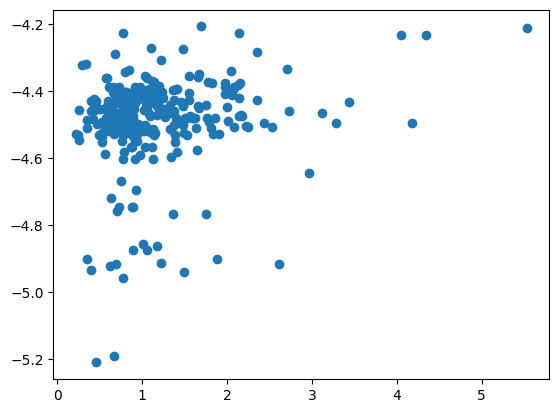

In [80]:
import matplotlib.pyplot as plt
plt.scatter(anage.longevity_quotient,anage.LLR)

In [81]:
anage

,Kingdom,Phylum,Class,Order,Family,Genus,Species,Common name,Female maturity (days),Male maturity (days),...,Data quality,IMR (per yr),MRDT (yrs),Metabolic rate (W),Body mass (g),Temperature (K),References,predicted_longevity,longevity_quotient,LLR
Species,,,,,,,,,,,,,,,,,,,,,
Echinops telfairi,Animalia,Chordata,Mammalia,Afrosoricida,Tenrecidae,Echinops,Echinops telfairi,Lesser hedgehog tenrec,365.0,365.0,...,acceptable,NaN,NaN,0.750,116.4,307.85,"36,148,434,455,542,610,671,678,680,731,1030,1103",12.109946,1.568958,-4.476727
Microgale talazaci,Animalia,Chordata,Mammalia,Afrosoricida,Tenrecidae,Microgale,Microgale talazaci,Talazac's shrew tenrec,639.0,639.0,...,acceptable,NaN,NaN,0.243,44.0,303.95,"36,420,434,455,731",9.977676,0.581298,-4.446214
Antilocapra americana,Animalia,Chordata,Mammalia,Artiodactyla,Antilocapridae,Antilocapra,Antilocapra americana,Pronghorn,547.0,547.0,...,acceptable,NaN,NaN,50.973,34779.3,311.15,"36,420,434,441,455,538,542,610,671,677,680,731...",28.008903,0.606950,-4.499999
Aepyceros melampus,Animalia,Chordata,Mammalia,Artiodactyla,Bovidae,Aepyceros,Aepyceros melampus,Impala,456.0,395.0,...,high,NaN,NaN,NaN,NaN,NaN,"434,455,610,671,676,677,680,731,1135",28.564892,0.896205,-4.409729
Ammotragus lervia,Animalia,Chordata,Mammalia,Artiodactyla,Bovidae,Ammotragus,Ammotragus lervia,Aoudad,335.0,NaN,...,acceptable,NaN,NaN,NaN,NaN,NaN,"434,455,610,671,677,680,731",31.118960,0.697324,-4.495565
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Solenodon paradoxus,Animalia,Chordata,Mammalia,Soricomorpha,Solenodontidae,Solenodon,Solenodon paradoxus,Hispaniolan solenodon,828.0,NaN,...,acceptable,NaN,NaN,NaN,NaN,NaN,"434,455,610,671,678,1308",15.694405,0.770975,-4.603682
Sorex araneus,Animalia,Chordata,Mammalia,Soricomorpha,Soricidae,Sorex,Sorex araneus,Eurasian shrew,198.0,335.0,...,acceptable,NaN,NaN,0.348,8.4,308.15,"36,420,434,455,504,542,610,671,678,680",7.698866,0.415646,-4.483153
Condylura cristata,Animalia,Chordata,Mammalia,Soricomorpha,Talpidae,Condylura,Condylura cristata,Star-nosed mole,304.0,304.0,...,questionable,NaN,NaN,0.615,49.0,310.85,"36,420,455,538,542,610,671,678,978",10.130833,0.246771,-4.532499


In [82]:
sp

,sp_id,common_name,scientific_name,clade,mammal,ncbi_taxonid,has_duplicate_taxonid,GenBank_id,scaffold_n50_kb,BUSCO_analysis,notes_NCBI,Old_or_New_World_monkey
sp_id,,,,,,,,,,,,
HLaciJub2,HLaciJub2,cheetah,Acinonyx jubatus,Carnivora,placental,32536,no,GCA_003709585.1,48500.0,"C:98.9%[S:98.4%,D:0.5%],F:0.3%,M:0.8%,n:14502",suppressed,NaN
HLacoCah1,HLacoCah1,Egyptian spiny mouse,Acomys cahirinus,Glires,placental,10068,no,GCA_004027535.1,65.4,NaN,not reference,NaN
HLacoRus1,HLacoRus1,golden spiny mouse,Acomys russatus,Glires,placental,60746,no,GCA_903995435.1,66500.0,"C:98.6%[S:97.0%,D:1.6%],F:0.4%,M:0.9%,n:13798",reference,NaN
HLaeoCin1,HLaeoCin1,hoary bat,Aeorestes cinereus,Chiroptera,placental,257879,no,GCA_011751065.1,35100.0,NaN,reference,NaN
HLaepMel1,HLaepMel1,impala,Aepyceros melampus,Artiodactyla,placental,9897,no,GCA_006408695.1,344.5,NaN,reference,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
HLvulVul1,HLvulVul1,red fox,Vulpes vulpes,Carnivora,placental,9627,no,GCA_003160815.1,12500.0,"C:96.5%[S:95.5%,D:1.1%],F:1.1%,M:2.3%,n:14502",reference,NaN
HLxerIna1,HLxerIna1,South African ground squirrel,Xerus inauris,Glires,placental,234690,no,GCA_004024805.1,83.9,NaN,reference,NaN
HLzalCal1,HLzalCal1,California sea lion,Zalophus californianus,Carnivora,placental,9704,no,GCA_009762305.1,146900.0,NaN,replaced by newer version (reference),NaN


In [87]:
for x in tree:
  x.name=sp.loc[x.name,'scientific_name']

In [88]:
print(tree)


                                       /-Zapus hudsonius
                                    /-|
                                   |   \-Jaculus jaculus
                                   |
                                   |                  /-Apodemus sylvaticus
                                   |                 |
                                   |               /-|      /-Mus musculus
                                   |              |  |   /-|
                                   |              |   \-|   \-Mus spicilegus
                                   |            /-|     |
                                   |           |  |      \-Mus caroli
                                   |           |  |
                                   |         /-|   \-Arvicanthis niloticus
                                   |        |  |
                                   |        |  |   /-Rattus rattus
                                   |        |   \-|
                                   |     

In [89]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize_scalar


def run_pgls(tree, anage, species_col=None):
    """
    Fit longevity_quotient ~ LLR with ML-estimated Pagel's lambda.

    species_col=None: species names are in anage.index.
    Otherwise, specify the column containing species names.

    Returns: fitted GLS model, estimated lambda, matched data.
    """
    normalize = lambda name: str(name).strip().replace(" ", "_")

    data = anage[["longevity_quotient", "LLR"]].copy()
    names = anage.index if species_col is None else anage[species_col]
    data.index = pd.Index([normalize(name) for name in names])

    data = data.apply(pd.to_numeric, errors="coerce")
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    if data.index.has_duplicates:
        raise ValueError("Species names in the dataframe must be unique.")

    root = tree.get_tree_root()
    tips = {}
    for tip in root.iter_leaves():
        name = normalize(tip.name)
        if name in tips:
            raise ValueError(f"Duplicate tree tip name: {name}")
        tips[name] = tip

    # Match species and preserve this order throughout
    matched = [name for name in data.index if name in tips]
    print(f"Matched {len(matched)} of {len(data)} species with complete data.")
    data = data.loc[matched].copy()

    if len(data) < 4:
        raise ValueError("Need at least four matched species.")
    if data["LLR"].nunique() < 2:
        raise ValueError("LLR must vary among matched species.")

    # Distance from the root to every node; ignore root.dist
    depth = {root: 0.0}
    for node in root.traverse("preorder"):
        if node is root:
            continue
        if not np.isfinite(node.dist) or node.dist < 0:
            raise ValueError("Tree branch lengths must be finite and nonnegative.")
        depth[node] = depth[node.up] + node.dist

    # Brownian covariance:
    # diagonal = root-to-tip distance
    # off-diagonal = root-to-MRCA distance
    nodes = [tips[name] for name in matched]
    n = len(nodes)
    C = np.zeros((n, n))

    for i, tip in enumerate(nodes):
        C[i, i] = depth[tip]
        for j in range(i):
            mrca = root.get_common_ancestor(tip, nodes[j])
            C[i, j] = C[j, i] = depth[mrca]

    if np.any(np.diag(C) <= 0):
        raise ValueError("All matched tips need positive root-to-tip distances.")

    # Rescaling the whole covariance does not change the GLS fit
    C /= np.mean(np.diag(C))
    diagonal = np.diag(np.diag(C))

    y = data["longevity_quotient"]
    X = sm.add_constant(data[["LLR"]], has_constant="add")

    def fit_at_lambda(lam):
        # Lambda scales off-diagonal covariances only
        covariance = diagonal + lam * (C - diagonal)
        return sm.GLS(y, X, sigma=covariance).fit()

    def negative_log_likelihood(lam):
        try:
            value = -fit_at_lambda(lam).llf
            return value if np.isfinite(value) else np.inf
        except np.linalg.LinAlgError:
            return np.inf

    optimization = minimize_scalar(
        negative_log_likelihood,
        bounds=(0.0, 1.0),
        method="bounded",
        options={"xatol": 1e-6},
    )
    if not optimization.success:
        raise RuntimeError(optimization.message)

    # Explicitly check both boundaries
    candidates = [0.0, float(optimization.x), 1.0]
    lambda_hat = min(candidates, key=negative_log_likelihood)

    if not np.isfinite(negative_log_likelihood(lambda_hat)):
        raise ValueError("Could not fit a nonsingular phylogenetic covariance.")

    result = fit_at_lambda(lambda_hat)

    print(f"\nEstimated Pagel's lambda: {lambda_hat:.4f}")
    print(result.summary())
    print(f"\nLLR slope: {result.params['LLR']:.6g}")
    print(f"LLR p-value: {result.pvalues['LLR']:.6g}")

    return result, lambda_hat, data


# If species names are the dataframe index:
pgls_result, lambda_hat, pgls_data = run_pgls(tree, anage)

# If species names are in a column instead:
# pgls_result, lambda_hat, pgls_data = run_pgls(
#     tree, anage, species_col="species"
# )

Matched 301 of 301 species with complete data.

Estimated Pagel's lambda: 0.9715
                            GLS Regression Results                            
Dep. Variable:     longevity_quotient   R-squared:                       0.000
Model:                            GLS   Adj. R-squared:                 -0.003
Method:                 Least Squares   F-statistic:                   0.08065
Date:                Thu, 12 Nov 2026   Prob (F-statistic):              0.777
Time:                        21:46:39   Log-Likelihood:                -194.99
No. Observations:                 301   AIC:                             394.0
Df Residuals:                     299   BIC:                             401.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------

In [58]:
spearmanr(list(anage.longevity_quotient), list(anage.LLR), nan_policy="omit")

SignificanceResult(statistic=np.float64(0.1626810685321412), pvalue=np.float64(0.004661489944615314))

In [56]:
spearmanr(list(anage.longevity_quotient),list(anage.LLR))

SignificanceResult(statistic=nan, pvalue=nan)

compute log-likelihood ratio scores (LLR) for all missense mutations with VESM

In [ ]:
get_LLR(protein_sequence, model)

<a id="visualize-results"></a>

## 4. Visualizing Results

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objs as go
from google.colab import output

AAorder=['K','R','H','E','D','N','Q','T','S','C','G','A','V','L','I','M','P','Y','F','W']

def plot_interactive(LLR,higher_than_wt=False,thresh=2,zmax=0,cmap='Viridis_r'):

  TITLE=''

  is_dark = output.eval_js('document.documentElement.matches("[theme=dark]")')
  template='plotly_dark' if is_dark else 'plotly_white'

  fig = px.imshow(LLR.values, x=LLR.columns, y=LLR.index, color_continuous_scale=cmap,zmax=zmax,
                  labels=dict(y="Amino acid change", x="Protein sequence", color="LLR"),
                  template=template,
                  title=TITLE)
  fig.update_xaxes(tickangle=-90,range=[0,99],rangeslider=dict(visible=True),dtick=1)
  fig.update_yaxes(dtick=1)
  fig.update_layout({
  'plot_bgcolor': 'rgba(0, 0, 0, 0)',
  'paper_bgcolor': 'rgba(0, 0, 0, 0)',
  },font={'family':'Arial','size':11},
  hoverlabel=dict(font=dict(family='Arial', size=14)))

  fig.update_traces(
      hovertemplate="<br>".join([
          "<b>%{x} %{y}</b>"+
          " (%{z:.2f})",
      ])+'<extra></extra>'
  )
  if higher_than_wt:
    hwt_x=[]
    hwt_y=[]
    cust=[]
    for i in LLR.columns:
      for j in list(LLR.index[LLR[i]>thresh]):
        hwt_x+=[i]
        hwt_y+=[j]
        cust+=[LLR.loc[j,i]]

    fig.add_trace(go.Scatter(
        x=hwt_x,
        y=hwt_y,
        customdata=cust,
        mode='markers',
        marker=dict(size=8),
        hovertemplate="<br>".join([
            "<b>%{x} %{y}</b>"+
            " (%{customdata:.2f})",
        ])+'<extra></extra>')
    )

  fig.show()


def plot_heatmap(LLR,figname=None,vmin=None):
  """
    Plot a per-residue score heatmap.
      Args:
          scores: 2D array-like of shape (positions, alphabet) or 1D positional scores.
          figname: Optional basename to save PNG.
          range: Color scale range for heatmap.
  """
  primaryLLR=LLR
  plt.figure(figsize=(int(np.round(primaryLLR.shape[1]*90/390)),5))
  sns.heatmap( primaryLLR ,cmap='viridis_r',xticklabels=True, yticklabels=True,vmax=0,vmin=vmin)
  if not figname is None:
    plt.savefig(f"{figname}.png", dpi=300,bbox_inches = 'tight')
  plt.show()

### Visualizing LLRs

In [ ]:
# MC4R
sequence = 'MVNSTHRGMHTSLHLWNRSSYRLHSNASESLGKGYSDGGCYEQLFVSPEVFVTLGVISLLENILVIVAIAKNKNLHSPMYFFICSLAVADMLVSVSNGSETIVITLLNSTDTDAQSFTVNIDNVIDSVICSSLLASICSLLSIAVDRYFTIFYALQYHNIMTVKRVGIIISCIWAACTVSGILFIIYSDSSAVIICLITMFFTMLALMASLYVHMFLMARLHIKRIAVLPGTGAIRQGANMKGAITLTILIGVFVVCWAPFFLHLIFYISCPQNPYCVCFMSHFNLYLILIMCNSIIDPLIYALRSQELRKTFKEIICCYPLGGLCDLSSRY'
plot_interactive(get_LLR(sequence, model))

<a id="visualize_structure"></a>

### Visualize on Structure

In [ ]:
!pip install --quiet py3Dmol biopython

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import py3Dmol
from Bio.SeqUtils import seq1
from Bio.PDB import PDBParser

def show_pdb(position_scores, pdb_file, width=800, height=600, surface=False):
    view = py3Dmol.view(width=width, height=height, js='https://3dmol.org/build/3Dmol.js')
    view.addModel(open(pdb_file, 'r').read(), 'pdb')
    sigmoid_scores = 1 / (1 + np.exp((0.6 * np.array(position_scores) + 6)))
    for i, value in enumerate(sigmoid_scores):
        rgba = plt.cm.coolwarm(value)
        hexcol = matplotlib.colors.rgb2hex(rgba[:3])
        view.setStyle({'resi': str(i+1)}, {'cartoon': {'color': hexcol}})
    view.setBackgroundColor('#383838')

    if surface:
        for i, value in enumerate(sigmoid_scores):
            rgba = plt.cm.coolwarm(value)
            hexcol = matplotlib.colors.rgb2hex(rgba[:3])
            view.addSurface(
                py3Dmol.VDW,
                { 'opacity': 0.7, 'color': hexcol },
                { 'resi': str(i+1) }
            )
        view.setBackgroundColor('white')


    view.zoomTo()
    return view

In [ ]:
import requests
def download_latest_af_pdb(uniprot_id, version_start=20, version_end=1, out_name=None):
    """
    Download the latest AF PDB model version for a UniProt ID.

    Args:
        uniprot_id (str): UniProt accession, e.g., "P12345"
        version_start (int): Highest version to check, e.g., 10
        version_end (int): Lowest version to check, e.g., 1
        out_name (str): Optional output filename. If None, use the server's name.
    """
    base_url = "https://alphafold.ebi.ac.uk/files"

    for v in range(version_start, version_end - 1, -1):
        url = f"{base_url}/AF-{uniprot_id}-F1-model_v{v}.pdb"
        head = requests.head(url)

        if head.status_code == 200:
            print(f"Found version v{v}: {url}")
            response = requests.get(url)
            response.raise_for_status()

            # Determine filename
            filename = out_name or url.split("/")[-1]
            with open(filename, "wb") as f:
                f.write(response.content)
            print(f"Downloaded to: {filename}")
            return filename

    print(f"No model found for UniProt ID '{uniprot_id}' in versions v{version_start}–v{version_end}.")
    return None

Example structure from AFDB

In [ ]:
uniprot_id = 'P32245'
pdb_file = download_latest_af_pdb(uniprot_id, version_start=10, version_end=4, out_name=None)

extract sequence from pdb

In [ ]:
sequence = "".join(
    seq1(res.get_resname())
    for res in PDBParser(QUIET=True).get_structure("model", pdb_file).get_residues()
    if res.id[0] == " "
)

average scores per position

In [ ]:
position_scores = get_LLR(sequence, model).values.mean(0)
show_pdb(position_scores,pdb_file)

<a id="download"></a>
## Download Prediction Scores

- **sequence**: input any amino acid sequence for LLR inference.
- **seq_name**: name the sequence for the file name (optional).
- **heatmap**: check if you want to download the LLR heatmap

In [ ]:
sequence = 'MVNSTHRGMHTSLHLWNRSSYRLHSNASESLGKGYSDGGCYEQLFVSPEVFVTLGVISLLENILVIVAIAKNKNLHSPMYFFICSLAVADMLVSVSNGSETIVITLLNSTDTDAQSFTVNIDNVIDSVICSSLLASICSLLSIAVDRYFTIFYALQYHNIMTVKRVGIIISCIWAACTVSGILFIIYSDSSAVIICLITMFFTMLALMASLYVHMFLMARLHIKRIAVLPGTGAIRQGANMKGAITLTILIGVFVVCWAPFFLHLIFYISCPQNPYCVCFMSHFNLYLILIMCNSIIDPLIYALRSQELRKTFKEIICCYPLGGLCDLSSRY' #@param {type:"string"}
seq_name = "" #@param {type:"string"}
heatmap = True #@param {type:"boolean"}

import hashlib, zipfile
from google.colab import files

def short_hash(seq, length=8):
    return hashlib.sha1(seq.encode()).hexdigest()[:length]

def meltLLR(LLR,gene_prefix=None,ignore_pos=False):
  vars = LLR.melt(ignore_index=False)
  vars['variant'] = [''.join(i.split(' '))+j for i,j in zip(vars['variable'],vars.index)]
  vars['score'] = vars['value']
  vars = vars.set_index('variant')
  if not ignore_pos:
    vars['pos'] = [int(i[1:-1]) for i in vars.index]
  del vars['variable'],vars['value']
  if gene_prefix is not None:
    vars.index=gene_prefix+'_'+vars.index
  return vars

base_name = f'vesm_LLR_{seq_name if len(seq_name) > 0 else short_hash(sequence)}'
csv_file = f"{base_name}.csv"
LLR_scores = get_LLR(sequence, model)

# save csv file
meltLLR(LLR_scores).to_csv(csv_file)

if heatmap:
    png_file = f"{base_name}.png"
    plot_heatmap(LLR_scores, figname=base_name, vmin=None)

    # Create results zip with both files
    zip_name = f"{base_name}_results.zip"
    with zipfile.ZipFile(zip_name, 'w') as zipf:
        zipf.write(csv_file)
        zipf.write(png_file)

file_name = zip_name if heatmap else csv_file

print(f"Saved results to: {file_name}")
files.download(file_name)

<a id="VESM3"></a>

# VESM3 Inference

Downloading the base ESM3-open model requires huggingface login

In [ ]:
from huggingface_hub import login
login()

In [ ]:
!pip install --quiet esm

remove previous model (necessary if using Colab's T4 GPU)

In [ ]:
if 'model' in globals():
    del model
    torch.cuda.empty_cache()
    import gc; gc.collect()

Load VESM3 checkpoint

In [ ]:
vesm3, _ = load_vesm("VESM3", local_dir=local_dir, device=device)

In [ ]:
def get_vesm3_LLR_sequence(sequence, esm3_model):
  from esm.sdk.api import ESMProtein
  protein = ESMProtein(sequence=sequence)
  tokens = esm3_model.encode(protein).sequence
  with torch.no_grad():
    logits =torch.log_softmax(esm3_model.forward(sequence_tokens=tokens.reshape(1,-1)).sequence_logits[0, :, :], dim=-1).cpu()
  tok = tokens.cpu()
  wt_norm = logits[np.arange(len(tok)), tok].unsqueeze(1)
  LLR = logits - wt_norm

  AAorder=['K','R','H','E','D','N','Q','T','S','C','G','A','V','L','I','M','P','Y','F','W']
  order = [esm3_model.tokenizers.sequence.vocab[x] for x in AAorder]
  LLR=LLR[1:-1,order].numpy()
  LLR_ = pd.DataFrame(LLR,columns=AAorder,index=list(sequence)).T
  LLR_.columns = [j.split('.')[0]+' '+str(i+1) for i,j in enumerate(LLR_.columns)]
  return LLR_


def get_vesm3_LLR_structure(pdb_file, esm3_model):
  from esm.sdk.api import ESMProtein
  protein = ESMProtein.from_pdb(pdb_file)
  tokens = esm3_model.encode(protein)
  seq_tokens = tokens.sequence
  struct_tokens = tokens.structure

  with torch.no_grad():
    logits =torch.log_softmax(esm3_model.forward(sequence_tokens=seq_tokens.reshape(1,-1), structure_tokens=struct_tokens.reshape(1,-1) ).sequence_logits[0, :, :], dim=-1).cpu()
  tok = seq_tokens.cpu()
  wt_norm = logits[np.arange(len(tok)), tok].unsqueeze(1)
  LLR = logits - wt_norm

  AAorder=['K','R','H','E','D','N','Q','T','S','C','G','A','V','L','I','M','P','Y','F','W']
  order = [esm3_model.tokenizers.sequence.vocab[x] for x in AAorder]
  LLR=LLR[1:-1,order].numpy()
  LLR_ = pd.DataFrame(LLR,columns=AAorder,index=list(sequence)).T
  LLR_.columns = [j.split('.')[0]+' '+str(i+1) for i,j in enumerate(LLR_.columns)]
  return LLR_

In [ ]:
### Example structure from AFDB
uniprot_id = 'P32245'
pdb_file = download_latest_af_pdb(uniprot_id, version_start=10, version_end=1, out_name=None)

In [ ]:
from Bio.PDB import PDBParser
from Bio.SeqUtils import seq1
# extract sequence from pdb
sequence = "".join(
    seq1(res.get_resname())
    for res in PDBParser(QUIET=True).get_structure("model", pdb_file).get_residues()
    if res.id[0] == " "
)

### Inference with sequence only

In [ ]:
LLR_seq = get_vesm3_LLR_sequence(sequence, vesm3)

### Inference with structure

In [ ]:
LLR_struct = get_vesm3_LLR_structure(pdb_file, vesm3)

### Visualize Results

Visualize differences between sequence- and structure- derived LLRs with VESM3

In [ ]:
# LLR_seq vs LLR_struct
import matplotlib
import matplotlib.pyplot as plt
plt.plot(LLR_seq.values.reshape(-1), LLR_struct.values.reshape(-1), '.')
plt.plot([-20, 5], [-20, 5], 'k--')
plt.xlabel('LLR from Sequence')
plt.ylabel('LLR from Structure')
plt.grid(True)
plt.show()

Plot the heatmap of differences

In [ ]:
def plot_diff_heatmap(diff,figname=None,range=4):
  plt.figure(figsize=(int(np.round(diff.shape[1]*90/390)),5))
  sns.heatmap( diff ,cmap='coolwarm_r',xticklabels=True, yticklabels=True,vmax=range,vmin=-range)
  if not figname is None:
    plt.savefig(f"{figname}.png", dpi=300,bbox_inches = 'tight')
  plt.show()

diff = LLR_struct - LLR_seq
plot_heatmap(LLR_seq)
threshold = -5
plot_diff_heatmap(diff[((LLR_struct<threshold) & (LLR_seq>threshold)) | ((LLR_struct>threshold) & (LLR_seq<threshold))])
plot_heatmap(LLR_struct)